# Indoor67 — Classical baseline
Exploration found **5,327 labeled images across 67 classes**, with 76–83 images per class and varying image dimensions. Use resized RGB pixels and color histograms with a linear SVM as a simple reference for later neural models. Reuse the exploration split: **4,261 training / 1,066 validation** images. Competition test images are excluded.

Run all cells using the project Python environment, from the repository root or `notebooks/`.

In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from tqdm.auto import tqdm
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data" / "train.csv").is_file()
             and (p / "src" / "dataset.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the repository root or notebooks directory.")
DATA_DIR = ROOT / "data"
IMAGE_ROOT = DATA_DIR / "images"
SEED = 42
print("Repository:", ROOT)

Repository: c:\Users\Spencer\General\daml-aitp


## 1. Validate and reuse the exploration split
Read the actual `id,file_path,label` manifest and compare it with the saved split. If it is missing or stale, rerun notebook 01. Keep relative paths and the same alphabetical label mapping. No new split is created here.

In [2]:
manifest = pd.read_csv(DATA_DIR / "train.csv", dtype=str).rename(
    columns={"id": "image_id", "file_path": "image_path"}
)
SPLIT_CSV = DATA_DIR / "validation_split.csv"
if not SPLIT_CSV.is_file():
    raise FileNotFoundError("Run notebook 01 to create data/validation_split.csv first.")
split_df = pd.read_csv(SPLIT_CSV, dtype=str)
keys = ["image_id", "image_path", "label"]
for name, frame in [("manifest", manifest), ("split", split_df)]:
    if not set(keys).issubset(frame.columns) or frame.empty:
        raise ValueError(f"Invalid {name}: expected nonempty {keys} columns.")
    if frame[keys].isna().any().any() or frame.image_id.duplicated().any() or frame.image_path.duplicated().any():
        raise ValueError(f"Missing or duplicate values in {name}.")
pd.testing.assert_frame_equal(
    manifest[keys].sort_values("image_id").reset_index(drop=True),
    split_df[keys].sort_values("image_id").reset_index(drop=True),
    obj="Manifest and saved split (rerun notebook 01 if data changed)"
)
if "split" not in split_df or split_df["split"].isna().any() or set(split_df["split"]) != {"train", "val"}:
    raise ValueError("Saved split must contain only train and val assignments.")
class_names = sorted(manifest.label.unique())
class_to_idx = {name: idx for idx, name in enumerate(class_names)}
declared_classes = pd.read_csv(DATA_DIR / "classes.csv", dtype=str).label
assert declared_classes.is_unique and set(class_names) == set(declared_classes)
train_df = split_df.loc[split_df["split"] == "train"].reset_index(drop=True)
val_df = split_df.loc[split_df["split"] == "val"].reset_index(drop=True)
assert set(train_df.image_id).isdisjoint(val_df.image_id)
assert set(train_df.label) == set(val_df.label) == set(class_names)
missing = [p for p in split_df.image_path if not (IMAGE_ROOT / p).is_file()]
if missing:
    raise FileNotFoundError(f"{len(missing)} missing images under {IMAGE_ROOT}: {missing[:5]}")
print(f"Train: {len(train_df):,}; validation: {len(val_df):,}; classes: {len(class_names)}")
display(pd.crosstab(split_df.label, split_df["split"]))

Train: 4,261; validation: 1,066; classes: 67


split,train,val
label,,
airport_inside,64,16
artstudio,64,16
auditorium,66,16
bakery,65,16
bar,66,16
...,...,...
tv_studio,62,16
videostore,63,15
waitingroom,63,16


## 2. Extract fixed-size features
Convert each image to RGB. Combine a 16 × 16 thumbnail (768 values) with normalized 16-bin histograms for each color channel (48 values). Extract train and validation features separately; fit all learned scaling on training data only.

In [3]:
THUMBNAIL_SIZE = (16, 16)
HIST_BINS = 16

def image_features(path):
    with Image.open(path) as image:
        rgb = image.convert("RGB")
        pixels = np.asarray(rgb, dtype=np.uint8)
        thumbnail = np.asarray(
            rgb.resize(THUMBNAIL_SIZE, Image.Resampling.BILINEAR), dtype=np.float32
        ).ravel() / 255.0
    histograms = [np.histogram(pixels[:, :, channel], bins=HIST_BINS, range=(0, 256))[0]
                  / pixels.shape[0] / pixels.shape[1] for channel in range(3)]
    return np.concatenate([thumbnail, *histograms]).astype(np.float32)

def extract_features(frame, description):
    return np.stack([image_features(IMAGE_ROOT / p)
                     for p in tqdm(frame.image_path, desc=description)])

start = perf_counter()
X_train = extract_features(train_df, "Training features")
X_val = extract_features(val_df, "Validation features")
y_train = train_df.label.map(class_to_idx).to_numpy()
y_val = val_df.label.map(class_to_idx).to_numpy()
feature_seconds = perf_counter() - start
assert X_train.shape[1] == X_val.shape[1] == 816
assert np.isfinite(X_train).all() and np.isfinite(X_val).all()
print("Feature shapes:", X_train.shape, X_val.shape)
print(f"Feature extraction: {feature_seconds:.1f} seconds")

Training features:   0%|          | 0/4261 [00:00<?, ?it/s]

Validation features:   0%|          | 0/1066 [00:00<?, ?it/s]

Feature shapes: (4261, 816) (1066, 816)
Feature extraction: 23.4 seconds


## 3. Fit and evaluate
Use fixed hyperparameters for this first baseline. Compare against a classifier that always predicts the most frequent training class. Accuracy and macro F1 are appropriate for the nearly balanced class counts. Validation data is used only for evaluation.

In [4]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
model = make_pipeline(
    StandardScaler(),
    LinearSVC(C=0.01, dual=False, max_iter=5000, random_state=SEED)
)
start = perf_counter()
model.fit(X_train, y_train)
fit_seconds = perf_counter() - start
y_pred = model.predict(X_val)
dummy_pred = dummy.predict(X_val)
metrics = pd.DataFrame([
    {"model": name, "accuracy": accuracy_score(y_val, predictions),
     "macro_f1": f1_score(y_val, predictions, labels=range(len(class_names)), average="macro", zero_division=0)}
    for name, predictions in [("most_frequent", dummy_pred), ("rgb_hist_linear_svm", y_pred)]
])
display(metrics)
print(f"SVM fitting: {fit_seconds:.1f} seconds")
report = pd.DataFrame(classification_report(
    y_val, y_pred, labels=range(len(class_names)), target_names=class_names,
    output_dict=True, zero_division=0
)).T
display(report)

,model,accuracy,macro_f1
0,most_frequent,0.015009,0.000441
1,rgb_hist_linear_svm,0.083490,0.071334


SVM fitting: 98.9 seconds


,precision,recall,f1-score,support
airport_inside,0.200000,0.125000,0.153846,16.00000
artstudio,0.083333,0.062500,0.071429,16.00000
auditorium,0.090909,0.062500,0.074074,16.00000
bakery,0.083333,0.062500,0.071429,16.00000
bar,0.071429,0.062500,0.066667,16.00000
...,...,...,...,...
warehouse,0.076923,0.062500,0.068966,16.00000
winecellar,0.076923,0.125000,0.095238,16.00000
accuracy,0.083490,0.083490,0.083490,0.08349
macro avg,0.067676,0.083154,0.071334,1066.00000


## 4. Inspect errors
Rows in the confusion matrix are true classes; columns are predicted classes. The sample shows reproducible validation mistakes for follow-up analysis.

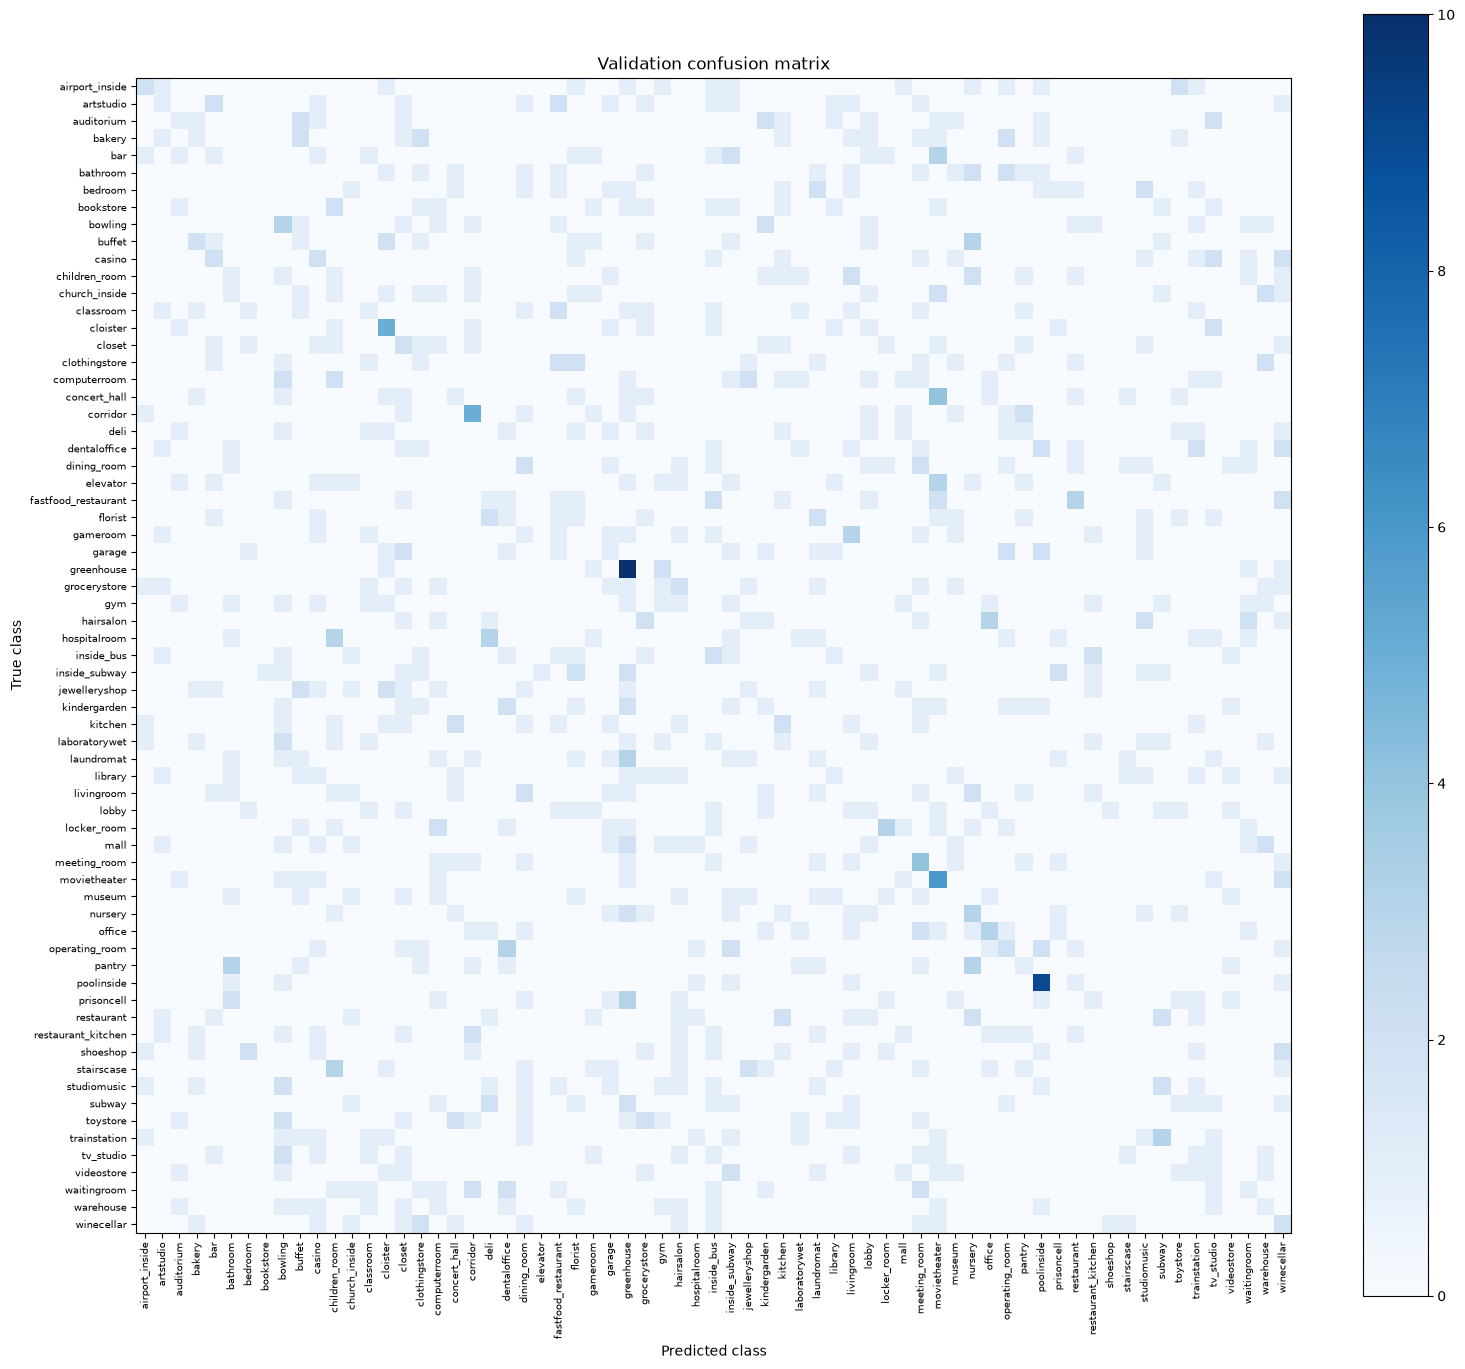

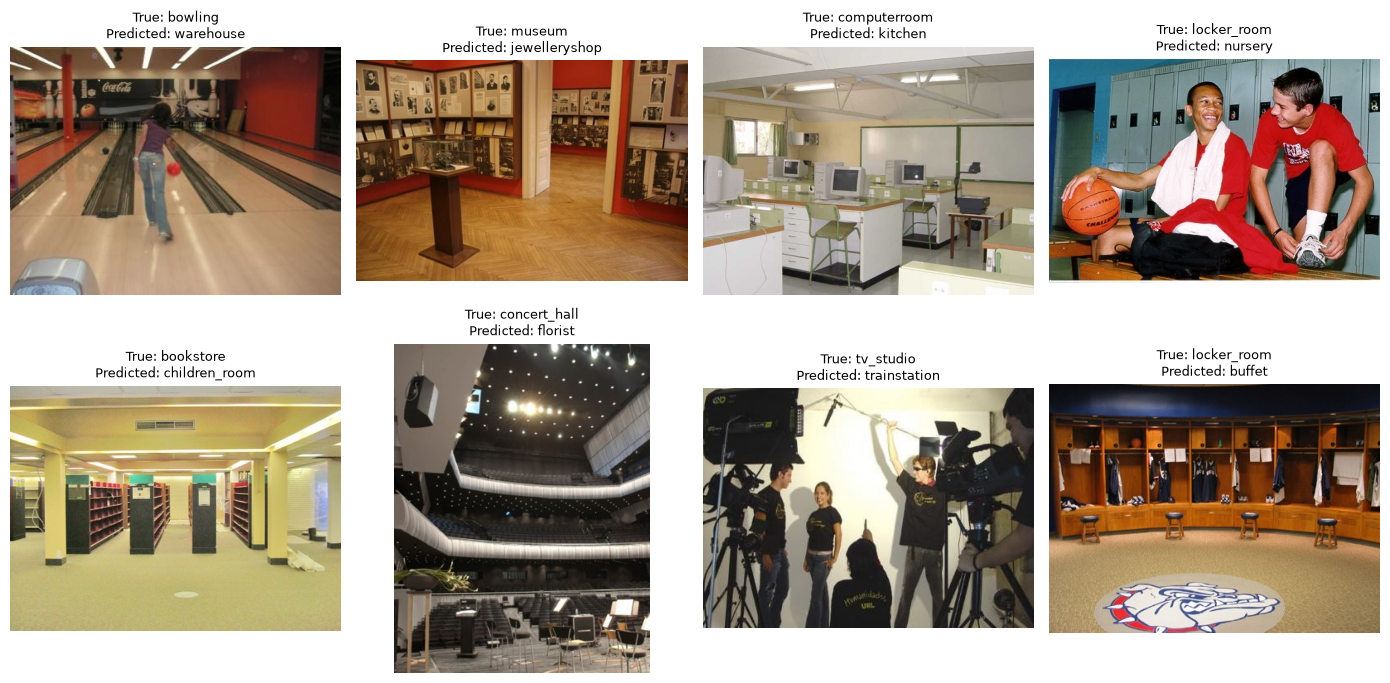

In [5]:
cm = confusion_matrix(y_val, y_pred, labels=range(len(class_names)))
fig, ax = plt.subplots(figsize=(16, 14))
plot = ax.imshow(cm, cmap="Blues")
ax.set(xticks=range(len(class_names)), yticks=range(len(class_names)),
       xticklabels=class_names, yticklabels=class_names,
       xlabel="Predicted class", ylabel="True class", title="Validation confusion matrix")
plt.setp(ax.get_xticklabels(), rotation=90, fontsize=7)
plt.setp(ax.get_yticklabels(), fontsize=7)
fig.colorbar(plot, ax=ax)
plt.tight_layout()
plt.show()

predictions = val_df[keys].copy()
predictions["predicted_label"] = np.asarray(class_names)[y_pred]
errors = predictions.loc[predictions.label != predictions.predicted_label]
if len(errors):
    sample = errors.sample(min(8, len(errors)), random_state=SEED)
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax in axes.flat:
        ax.axis("off")
    for ax, row in zip(axes.flat, sample.itertuples()):
        with Image.open(IMAGE_ROOT / row.image_path) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(f"True: {row.label}\nPredicted: {row.predicted_label}", fontsize=9)
    plt.tight_layout()
    plt.show()
else:
    print("No validation errors.")

## 5. Save the baseline
Save the fitted training-only pipeline, feature configuration, label mapping, split fingerprint, validation predictions and metrics. Rerunning replaces this baseline's artifacts. Later models should use the same split. To use the saved pipeline, apply `image_features` with the saved feature settings before calling `predict`.

In [6]:
CHECKPOINT_DIR = ROOT / "checkpoints"
EXPERIMENT_DIR = ROOT / "experiments"
CHECKPOINT_DIR.mkdir(exist_ok=True)
EXPERIMENT_DIR.mkdir(exist_ok=True)
split_sha256 = hashlib.sha256(SPLIT_CSV.read_bytes()).hexdigest()
model_path = CHECKPOINT_DIR / "baseline_rgb_hist_linear_svm.joblib"
joblib.dump({
    "pipeline": model, "class_names": class_names, "class_to_idx": class_to_idx,
    "thumbnail_size": THUMBNAIL_SIZE, "hist_bins": HIST_BINS,
    "resize_resampling": "BILINEAR", "seed": SEED, "split_sha256": split_sha256
}, model_path)
predictions.to_csv(EXPERIMENT_DIR / "baseline_validation_predictions.csv", index=False)
report.to_csv(EXPERIMENT_DIR / "baseline_classification_report.csv")
metrics_to_save = metrics.assign(
    seed=SEED, train_images=len(train_df), val_images=len(val_df),
    classes=len(class_names), split_sha256=split_sha256
)
metrics_to_save.to_csv(EXPERIMENT_DIR / "baseline_metrics.csv", index=False)
print("Saved model:", model_path)
display(metrics_to_save)

Saved model: c:\Users\Spencer\General\daml-aitp\checkpoints\baseline_rgb_hist_linear_svm.joblib


,model,accuracy,macro_f1,seed,train_images,val_images,classes,split_sha256
0,most_frequent,0.015009,0.000441,42,4261,1066,67,8ebb7c00c22351133647eaba1f2b0d96098da7eaef785d...
1,rgb_hist_linear_svm,0.083490,0.071334,42,4261,1066,67,8ebb7c00c22351133647eaba1f2b0d96098da7eaef785d...
